# v33 — PF出力の「モード推定」診断(安い診断・PF再実行なし)
192本(32seed×6ソース)の選択は v20 で死亡済みなので、**井戸レベルの2〜3モード(datumバンドル)推定**に落とす。
参照 = v28 parquet の 9本(tw/self/nbr × pfパラメータ1..3)の井戸別オフセット `d_r = median(ref − blend)`。

**3つの go/no-go ゲート**:
1. **モードoracle**: 井戸ごと候補モード(+stay)から正解を選べた時の overall。自由定数シフト上限(=井戸別最適シフト)と比べ、候補にどれだけ正解が入っているか。
2. **特徴AUC > 0.6**: 外部情報系(投票率/nbr支持/NN-GBM不一致方向)でオラクルモードを当てられるか。GR尤度系(対照群)は死ぬはず=v20の再確認。
3. **学習ゲートOOF < 6.7960**(=vote-hedge)。超えたら submit 実装へ、ダメなら撤退。

基準: blend OOF 6.8711 / vote-hedge 6.7960 / 軌跡oracle(参考)≈5.0。


In [1]:
# ===== ロード: blend OOF(基準) + 参照PF 9本の井戸別オフセット観測 =====
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = "Meiryo"; matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
V28_ART = PROJECT / "v28" / "artifacts_v28"
V29_ART = PROJECT / "v29" / "artifacts_v29"
V29B    = PROJECT / "v29" / "artifacts_v29b"
V32_ART = PROJECT / "v32" / "artifacts_v32"
ART = PROJECT / "v33" / "artifacts_v33"; ART.mkdir(parents=True, exist_ok=True)

REF_COLS = [("tw", 1, "pf_ancc_1"), ("tw", 2, "pf_ancc_2"), ("tw", 3, "pf_ancc_3"),
            ("self", 1, "pf_self_1"), ("self", 2, "pf_self_2"), ("self", 3, "pf_self_3"),
            ("nbr", 1, "pf_nbr_1"), ("nbr", 2, "pf_nbr_2"), ("nbr", 3, "pf_nbr_3")]
STD_COLS = ["pf_ancc_std_1", "pf_ancc_std_2", "pf_ancc_std_3",
            "pf_self_std_1", "pf_self_std_2", "pf_self_std_3",
            "pf_nbr_std_1", "pf_nbr_std_2", "pf_nbr_std_3"]
CTRL_COLS = ["pf_mean_gr_abs0", "pf_mean_gr_best_resid"]  # GR尤度系=v20で死んだ信号(対照群)
cols = (["well", "target", "last_known_tvt", "md_since", "pf_ancc",
         "pf_nbr_has", "pf_nbr_nrefs", "pf_nbr_nndist"]
        + [c for _, _, c in REF_COLS] + STD_COLS + CTRL_COLS)
tbl = pq.read_table(V28_ART / "data" / "train.parquet", columns=cols)
col = {c: tbl.column(c).to_numpy(zero_copy_only=False) for c in cols if c != "well"}
g = tbl.column("well").to_pandas().to_numpy()
y   = col["target"].astype(np.float64)
lk  = col["last_known_tvt"].astype(np.float64)
mds = col["md_since"].astype(np.float64)
pfa = col["pf_ancc"].astype(np.float64)
tvt_true = lk + y

gbm = np.load(V29_ART / "gbm_oof.npy")
nnz = np.load(V29B / "nn_oof_combo.npz")
nn_ens = np.mean([nnz[k] for k in nnz.files], axis=0)
w_nn = float(json.loads((V29B / "results.json").read_text())["combo"]["blend_w"])
pp = json.loads((V28_ART / "pp_params.json").read_text())
def apply_pp(res):
    dd = res * (1 - pp["w_pf"]) + (pfa - lk) * pp["w_pf"]
    return lk + dd * (1.0 - np.exp(-np.maximum(mds, 0.0) / float(pp["tau"]))) * pp.get("alpha", 1.0)
blend  = apply_pp((1 - w_nn) * gbm + w_nn * nn_ens)
pred_g = apply_pp(gbm)      # GBM単体(pp後) — NNとのdatum不一致特徴用
pred_n = apply_pp(nn_ens)   # NN単体(pp後)

wid = pd.unique(g)
rows_of = {w: np.where(g == w)[0] for w in wid}
def rmse(e):
    e = e[np.isfinite(e)]
    return float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
e0 = blend - tvt_true
base_overall = rmse(e0)
per_base = {w: rmse(e0[rows_of[w]]) for w in wid}
HARD = set(pd.read_csv(V32_ART / "hardcore_diag.csv", index_col=0).query(
    "rmse_prior >= 10 and abs(bias) > 8").index) & set(wid)
print(f"blend OOF overall = {base_overall:.4f}(基準) | wells {len(wid)} | 硬い核 {len(HARD)}本")

# 井戸×参照のオフセット観測(真値不使用)。tail = 井戸後半だけの median(biasが最も素直に出る区間)
OBS = {}
for w in wid:
    r = rows_of[w]
    o = np.argsort(mds[r]); r_tail = r[o[len(o) // 2:]]
    nbr_ok = np.nanmean(col["pf_nbr_has"][r]) > 0.5
    refs = {}
    for src, pset, c in REF_COLS:
        if src == "nbr" and not nbr_ok:
            continue
        v = col[c][r].astype(np.float64) - blend[r]
        if np.isfinite(v).sum() < max(10, 0.3 * len(r)):
            continue
        vt = col[c][r_tail].astype(np.float64) - blend[r_tail]
        refs[(src, pset)] = (float(np.nanmedian(v)), float(np.nanmedian(vt)))
    OBS[w] = refs
n_refs = np.array([len(OBS[w]) for w in wid])
print(f"参照本数/井戸: median={np.median(n_refs):.0f} | 9本={int(np.sum(n_refs == 9))}井戸 | <=3本={int(np.sum(n_refs <= 3))}井戸")


blend OOF overall = 6.8711(基準) | wells 773 | 硬い核 27本
参照本数/井戸: median=9 | 9本=583井戸 | <=3本=0井戸


overall: base 6.8711 → モードoracle 6.2403 / 自由シフトoracle 4.4494(定数シフト上限)
回収率: モードoracleは自由シフト上限の 26% を回収
非ゼロ選択井戸 50 / 773(硬い核では 9/27)
(参考: 軌跡oracle≈5.0 は seedまぐれ込み。定数シフトで届く床が上の自由シフト値)


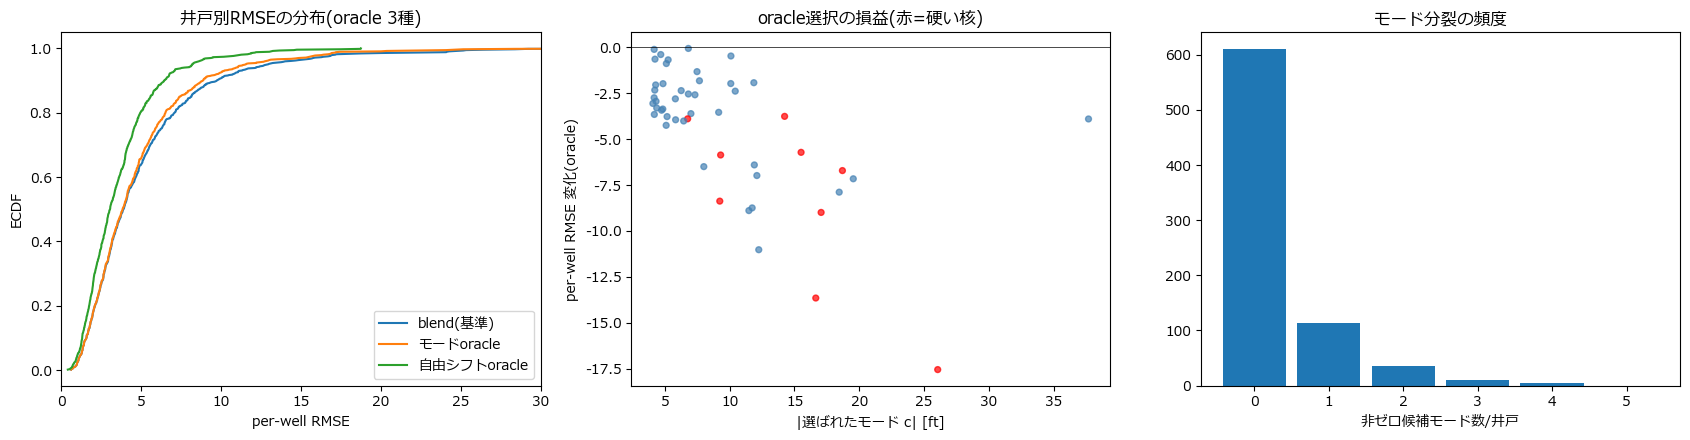

In [2]:
# ===== ゲート1: モード分解(1Dギャップ連結)と3つのオラクル =====
GAP_LINK = 8.0                   # 参照オフセット同士がこれ以上離れたら別モード
MODE_MIN, MODE_MAX = 4.0, 60.0   # 候補モードの振幅帯(|c|<4はstayと同義, >60は暴走扱い)

def cluster_modes(refs):
    items = sorted(refs.items(), key=lambda kv: kv[1][0])
    if not items:
        return []
    groups, cur = [], [items[0]]
    for it in items[1:]:
        if it[1][0] - cur[-1][1][0] > GAP_LINK:
            groups.append(cur); cur = [it]
        else:
            cur.append(it)
    groups.append(cur)
    out = []
    for m in groups:
        ds = [v[0] for _, v in m]
        out.append(dict(c=float(np.median(ds)), members=[k for k, _ in m],
                        spread=float(np.std(ds)) if len(ds) > 1 else 0.0,
                        d_tail=float(np.median([v[1] for _, v in m]))))
    return out

MODES = {w: cluster_modes(OBS[w]) for w in wid}
pick, per_or, per_fs, n_cand = {}, {}, {}, {}
e_or, e_fs = e0.copy(), e0.copy()
for w in wid:
    r = rows_of[w]; ew = e0[r]
    cands = [0.0] + [m["c"] for m in MODES[w] if MODE_MIN <= abs(m["c"]) <= MODE_MAX]
    n_cand[w] = len(cands) - 1
    scores = [rmse(ew + c) for c in cands]
    j = int(np.argmin(scores))
    pick[w] = cands[j]; per_or[w] = scores[j]
    e_or[r] = ew + pick[w]
    mu = np.nanmean(ew)
    per_fs[w] = rmse(ew - mu); e_fs[r] = ew - mu

or_overall, fs_overall = rmse(e_or - 0), rmse(e_fs - 0)
nz = [w for w in wid if pick[w] != 0.0]
print(f"overall: base {base_overall:.4f} → モードoracle {or_overall:.4f} / 自由シフトoracle {fs_overall:.4f}(定数シフト上限)")
print(f"回収率: モードoracleは自由シフト上限の {100 * (base_overall - or_overall) / max(base_overall - fs_overall, 1e-9):.0f}% を回収")
print(f"非ゼロ選択井戸 {len(nz)} / {len(wid)}(硬い核では {sum(1 for w in nz if w in HARD)}/{len(HARD)})")
print(f"(参考: 軌跡oracle≈5.0 は seedまぐれ込み。定数シフトで届く床が上の自由シフト値)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for lab, pw in [("blend(基準)", per_base), ("モードoracle", per_or), ("自由シフトoracle", per_fs)]:
    v = np.sort([pw[w] for w in wid])
    ax[0].plot(v, np.arange(1, len(v) + 1) / len(v), label=lab)
ax[0].set_xlim(0, 30); ax[0].set_xlabel("per-well RMSE"); ax[0].set_ylabel("ECDF"); ax[0].legend()
ax[0].set_title("井戸別RMSEの分布(oracle 3種)")
xs = [abs(pick[w]) for w in nz]; ys = [per_or[w] - per_base[w] for w in nz]
cs = ["red" if w in HARD else "steelblue" for w in nz]
ax[1].scatter(xs, ys, c=cs, s=18, alpha=0.7); ax[1].axhline(0, c="k", lw=0.5)
ax[1].set_xlabel("|選ばれたモード c| [ft]"); ax[1].set_ylabel("per-well RMSE 変化(oracle)")
ax[1].set_title("oracle選択の損益(赤=硬い核)")
ax[2].hist([n_cand[w] for w in wid], bins=np.arange(-0.5, 6.5), rwidth=0.85)
ax[2].set_xlabel("非ゼロ候補モード数/井戸"); ax[2].set_title("モード分裂の頻度")
plt.tight_layout(); plt.show()


候補モード 230行 / 分裂井戸 163 / 正解モード(=動くのが正解) 50
ext_vote     0.821
vote         0.788
n_pset       0.742
stay_share   0.730
n_src        0.725
spread       0.720
has_self     0.711
c_abs        0.705
tail_dev     0.626
nrefs        0.613
has_tw       0.601
has_opp      0.594
nndist       0.582
d_gnn        0.578
gr_bres      0.549
has_nbr      0.533
n_rows       0.531
gr_abs0      0.531
gnn_align    0.514
seed_std     0.512


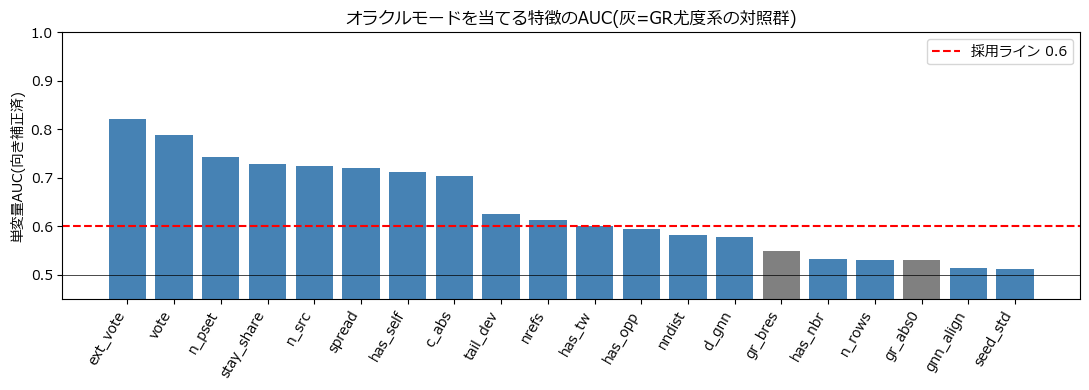

In [3]:
# ===== ゲート2: 井戸×候補モードのテーブルと特徴AUC(真値不使用の特徴のみ) =====
from sklearn.metrics import roc_auc_score

wellstat = {}
for w in wid:
    r = rows_of[w]
    wellstat[w] = dict(
        seed_std=float(np.nanmean([np.nanmedian(col[c][r]) for c in STD_COLS])),  # seed分裂の代理
        nrefs=float(np.nanmedian(col["pf_nbr_nrefs"][r])),
        nndist=float(np.nanmedian(col["pf_nbr_nndist"][r])),
        gr_abs0=float(np.nanmedian(col["pf_mean_gr_abs0"][r])),        # 対照群(死ぬはず)
        gr_bres=float(np.nanmedian(col["pf_mean_gr_best_resid"][r])),  # 対照群(死ぬはず)
        d_gnn=float(np.nanmedian(pred_n[r] - pred_g[r])),              # NN−GBM のdatum不一致
        n_rows=float(len(r)))

rows = []
for w in wid:
    ms = [m for m in MODES[w] if MODE_MIN <= abs(m["c"]) <= MODE_MAX]
    if not ms:
        continue
    nref = max(len(OBS[w]), 1)
    n_ext = sum(1 for s, _ in OBS[w] if s != "tw")
    stay_n = sum(len(m["members"]) for m in MODES[w] if abs(m["c"]) < MODE_MIN)
    for m in ms:
        srcs = {s for s, _ in m["members"]}; psets = {p for _, p in m["members"]}
        ext_in = sum(1 for s, _ in m["members"] if s != "tw")
        ws_ = wellstat[w]
        rows.append(dict(
            well=w, c=m["c"], gain=per_base[w] - rmse(e0[rows_of[w]] + m["c"]),
            y=int(pick[w] != 0.0 and abs(pick[w] - m["c"]) < 1e-9),
            vote=len(m["members"]) / nref, ext_vote=(ext_in / n_ext) if n_ext else 0.0,
            stay_share=stay_n / nref,
            n_src=len(srcs), has_nbr=int("nbr" in srcs), has_self=int("self" in srcs),
            has_tw=int("tw" in srcs), n_pset=len(psets),
            c_abs=abs(m["c"]), spread=m["spread"], tail_dev=abs(m["d_tail"] - m["c"]),
            has_opp=int(any(np.sign(x["c"]) != np.sign(m["c"]) for x in ms if x is not m)),
            gnn_align=float(np.sign(m["c"]) * ws_["d_gnn"]),  # NN-GBM不一致がこのモード方向を指すか
            **ws_))
TBL = pd.DataFrame(rows)
print(f"候補モード {len(TBL)}行 / 分裂井戸 {TBL['well'].nunique()} / 正解モード(=動くのが正解) {int(TBL['y'].sum())}")

FEATS = ["vote", "ext_vote", "stay_share", "n_src", "has_nbr", "has_self", "has_tw",
         "n_pset", "c_abs", "spread", "tail_dev", "has_opp", "gnn_align",
         "seed_std", "nrefs", "nndist", "n_rows", "d_gnn", "gr_abs0", "gr_bres"]
aucs = {}
for f in FEATS:
    v = TBL[f].to_numpy(dtype=float); m_ = np.isfinite(v)
    if TBL["y"][m_].nunique() < 2:
        continue
    a = roc_auc_score(TBL["y"][m_], v[m_]); aucs[f] = max(a, 1 - a)
A = pd.Series(aucs).sort_values(ascending=False)
print(A.to_string(float_format="%.3f"))

fig, ax = plt.subplots(figsize=(11, 4))
colors = ["gray" if f in ("gr_abs0", "gr_bres") else "steelblue" for f in A.index]
ax.bar(A.index, A.values, color=colors)
ax.axhline(0.6, c="r", ls="--", label="採用ライン 0.6"); ax.axhline(0.5, c="k", lw=0.5)
ax.set_ylabel("単変量AUC(向き補正済)"); ax.set_ylim(0.45, 1.0)
ax.set_title("オラクルモードを当てる特徴のAUC(灰=GR尤度系の対照群)")
plt.xticks(rotation=60, ha="right"); ax.legend(); plt.tight_layout(); plt.show()


OOF AUC: LGBM 0.768 / Logistic 0.801(サンプル230行なのでLogistic重視)
基準: blend 6.8711 / vote-hedge 6.7960 / モードoracle 6.2403
                  rule  overall
p_lgb hard λ0.4 p>=0.4 6.749176
p_lgb hard λ0.4 p>=0.5 6.760831
p_lgb hard λ0.4 p>=0.6 6.781456
       p_lgb soft λ0.6 6.783359
       p_lgb soft λ0.4 6.792511
       p_lgb soft λ0.8 6.794480
       p_lgb soft λ1.0 6.825773
p_log hard λ0.4 p>=0.4 6.844705
       p_log soft λ0.4 6.845697
       p_log soft λ0.6 6.854933
p_log hard λ0.4 p>=0.6 6.867678
p_log hard λ0.4 p>=0.5 6.867945
       p_log soft λ0.8 6.878755
       p_log soft λ1.0 6.917014


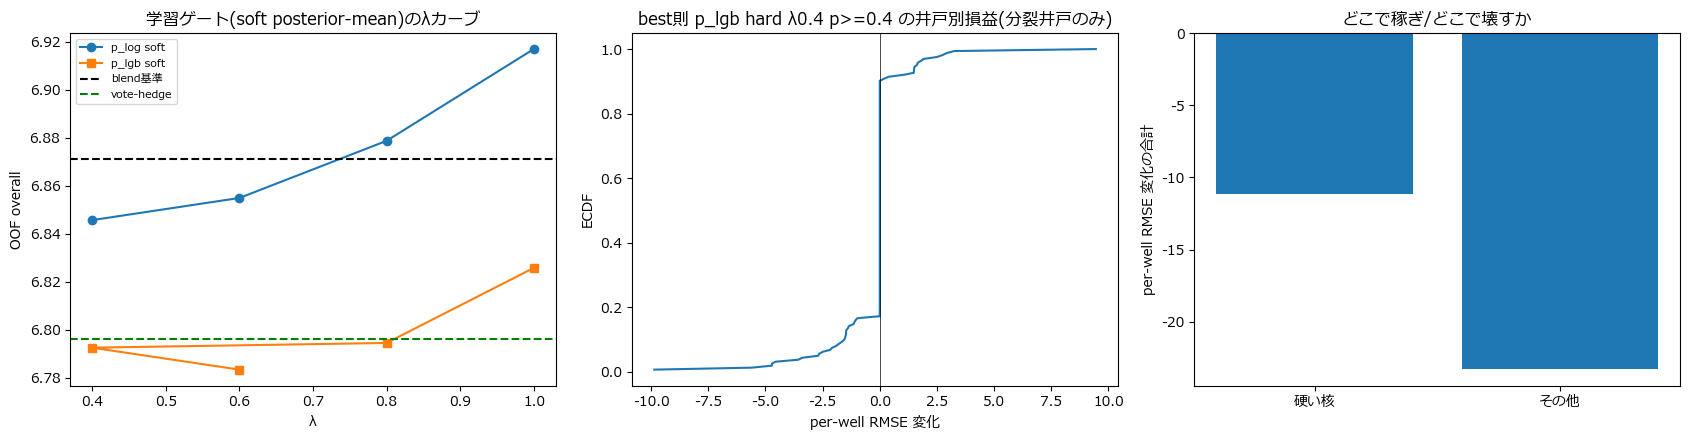

悪化上位(+1.0以上):
  201661b5: 13.2 → 22.7
  73348914: 11.1 → 14.3
  abf460d2: 7.5 → 10.4
  9283ae69: 7.1 → 9.8
  ee4aecac: 6.0 → 8.5
  1b82b665: 9.4 → 11.3
  91db7070: 24.7 → 26.5
  70925e23: 29.2 → 30.9
  1b6ba517: 10.0 → 11.6
  49dbc14c: 12.2 → 13.7
  a87433c9: 7.2 → 8.7
  11d0f5ac: 3.2 → 4.7
  d924e971: 11.1 → 12.6
  7e208414: 3.4 → 4.4


In [4]:
# ===== ゲート3: 学習ゲート(GroupKFold OOF) → posterior-mean シフトの overall =====
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

Xf = [f for f in FEATS if f not in ("gr_abs0", "gr_bres")]  # 対照群は本番特徴から除外
X = np.nan_to_num(TBL[Xf].to_numpy(dtype=float), nan=-999.0)
yb = TBL["y"].to_numpy(); grp = TBL["well"].to_numpy()
p_lgb = np.zeros(len(TBL)); p_log = np.zeros(len(TBL))
for tr, va in GroupKFold(5).split(X, yb, grp):
    mdl = lgb.LGBMClassifier(n_estimators=250, learning_rate=0.05, num_leaves=7,
                             min_child_samples=25, subsample=0.9, colsample_bytree=0.8,
                             reg_lambda=1.0, verbose=-1)
    mdl.fit(X[tr], yb[tr]); p_lgb[va] = mdl.predict_proba(X[va])[:, 1]
    sc = StandardScaler().fit(X[tr])
    lo = LogisticRegression(C=0.3, max_iter=2000).fit(sc.transform(X[tr]), yb[tr])
    p_log[va] = lo.predict_proba(sc.transform(X[va]))[:, 1]
auc_lgb = roc_auc_score(yb, p_lgb); auc_log = roc_auc_score(yb, p_log)
print(f"OOF AUC: LGBM {auc_lgb:.3f} / Logistic {auc_log:.3f}(サンプル{len(TBL)}行なのでLogistic重視)")

TBL["p_lgb"], TBL["p_log"] = p_lgb, p_log
def apply_gate(pcolname, lam, thr=None, soft=True):
    out = blend.copy()
    for w, sub in TBL.groupby("well"):
        b = sub.iloc[int(np.argmax(sub[pcolname].to_numpy()))]
        if thr is not None and b[pcolname] < thr:
            continue
        out[rows_of[w]] += lam * (float(b[pcolname]) * b["c"] if soft else b["c"])
    return out

res = []
for name in ["p_log", "p_lgb"]:
    for lam in [0.4, 0.6, 0.8, 1.0]:
        res.append(dict(rule=f"{name} soft λ{lam}", pcol=name, lam=lam, thr=np.nan, soft=True,
                        overall=rmse(apply_gate(name, lam, None, True) - tvt_true)))
    for thr in [0.4, 0.5, 0.6]:
        res.append(dict(rule=f"{name} hard λ0.4 p>={thr}", pcol=name, lam=0.4, thr=thr, soft=False,
                        overall=rmse(apply_gate(name, 0.4, thr, False) - tvt_true)))
R = pd.DataFrame(res).sort_values("overall")
print(f"基準: blend {base_overall:.4f} / vote-hedge 6.7960 / モードoracle {or_overall:.4f}")
print(R[["rule", "overall"]].to_string(index=False))

b = R.iloc[0]
out = apply_gate(b["pcol"], b["lam"], None if not np.isfinite(b["thr"]) else b["thr"], bool(b["soft"]))
per_new = {w: rmse((out - tvt_true)[rows_of[w]]) for w in wid}
gated = sorted(TBL["well"].unique(), key=lambda w: per_new[w] - per_base[w])
dd = {w: per_new[w] - per_base[w] for w in gated}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, mark in [("p_log", "o"), ("p_lgb", "s")]:
    sub = R[(R["pcol"] == name) & R["soft"]]
    ax[0].plot(sub["lam"], sub["overall"], mark + "-", label=f"{name} soft")
ax[0].axhline(base_overall, c="k", ls="--", label="blend基準")
ax[0].axhline(6.7960, c="g", ls="--", label="vote-hedge")
ax[0].set_xlabel("λ"); ax[0].set_ylabel("OOF overall"); ax[0].legend(fontsize=8)
ax[0].set_title("学習ゲート(soft posterior-mean)のλカーブ")
v = np.sort(list(dd.values()))
ax[1].plot(v, np.arange(1, len(v) + 1) / len(v)); ax[1].axvline(0, c="k", lw=0.5)
ax[1].set_xlabel("per-well RMSE 変化"); ax[1].set_ylabel("ECDF")
ax[1].set_title(f"best則 {b['rule']} の井戸別損益(分裂井戸のみ)")
hard_gain = sum(dd[w] for w in gated if w in HARD)
rest_gain = sum(dd[w] for w in gated if w not in HARD)
ax[2].bar(["硬い核", "その他"], [hard_gain, rest_gain])
ax[2].set_ylabel("per-well RMSE 変化の合計"); ax[2].set_title("どこで稼ぎ/どこで壊すか")
plt.tight_layout(); plt.show()
print("悪化上位(+1.0以上):")
for w in sorted(gated, key=lambda w: -dd[w]):
    if dd[w] > 1.0:
        print(f"  {w}: {per_base[w]:.1f} → {per_new[w]:.1f}")


In [5]:
# ===== 判定サマリと保存 =====
verdict = dict(
    base_overall=base_overall, mode_oracle=or_overall, free_shift_oracle=fs_overall,
    recovery_pct=100 * (base_overall - or_overall) / max(base_overall - fs_overall, 1e-9),
    auc_univariate={k: float(v) for k, v in A.items()},
    auc_oof=dict(lgb=float(auc_lgb), log=float(auc_log)),
    best_rule=str(R.iloc[0]["rule"]), best_overall=float(R.iloc[0]["overall"]),
    ref_vote_hedge=6.7960, n_split_wells=int(TBL["well"].nunique()))
(ART / "mode_gate_results.json").write_text(json.dumps(verdict, indent=1))
TBL.to_csv(ART / "mode_table.csv", index=False)

ext_feats = ["vote", "ext_vote", "has_nbr", "gnn_align", "n_src"]
auc_ext = max(A.get(f, 0.5) for f in ext_feats)
print("=" * 70)
print(f"ゲート1(候補にどれだけ正解があるか): モードoracle {or_overall:.4f}"
      f"(自由シフト上限 {fs_overall:.4f} の {verdict['recovery_pct']:.0f}% 回収)")
print(f"ゲート2(外部情報AUC): 最良 {auc_ext:.3f} → {'PASS' if auc_ext > 0.6 else 'FAIL(撤退)'}"
      f" | 対照群GR尤度: {A.get('gr_abs0', float('nan')):.3f}/{A.get('gr_bres', float('nan')):.3f}")
print(f"ゲート3(学習ゲートOOF): {R.iloc[0]['overall']:.4f} vs vote-hedge 6.7960 →"
      f" {'PASS(submit実装へ)' if R.iloc[0]['overall'] < 6.7960 else 'FAIL(手書きhedge据え置き)'}")
print("保存:", ART / "mode_gate_results.json", "/", ART / "mode_table.csv")


ゲート1(候補にどれだけ正解があるか): モードoracle 6.2403(自由シフト上限 4.4494 の 26% 回収)
ゲート2(外部情報AUC): 最良 0.821 → PASS | 対照群GR尤度: 0.531/0.549
ゲート3(学習ゲートOOF): 6.7492 vs vote-hedge 6.7960 → PASS(submit実装へ)
保存: C:\Users\kosaka256\Documents\rogii_claude\v33\artifacts_v33\mode_gate_results.json / C:\Users\kosaka256\Documents\rogii_claude\v33\artifacts_v33\mode_table.csv
